# To test the effect of flat assumption in our WCS construction

In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_y3_utils import stats_code
from hsc_y3_utils import map_utils
import tqdm

In [2]:
name_fields = ['XMM', 'VVDS','GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8, 25,23,7,26,13] # of each corresponding field

field = 'GAMA15H'
tomo_bin = 1

dat = np.concat([
    fits.getdata(f'/home/hedi/HSCNG/data/real/hscy3_shape_chopped_{field}_{n_patch}.fits')
    for n_patch in range(number_patches[name_fields.index(field)])
])
dat = dat[np.isin(dat['hsc_y3_zbin'], tomo_bin)]

In [3]:
def coord2pix(ra, dec):
    """
    performing the WCS construction, and transforming the coordinates to pixel space
    """
    w, (nx, ny) = map_utils.set_wcs_shape(ra, dec, 0.5, 1)
    flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)
    x, y, index = flatgrid.pos2pix2d(ra=ra, dec=dec)
    return w, x, y

def rotate_to_00(ra, dec):
    """
    rotate the coordinates so that the centre is at (0, 0)
    """
    coord = SkyCoord(ra=ra*u.deg, dec=dec*u.deg)
    center = SkyCoord(ra=np.mean(ra)*u.deg, dec=np.mean(dec)*u.deg)

    rot_frame = center.skyoffset_frame()
    coord_rot = coord.transform_to(rot_frame)

    ra_rot = coord_rot.lon.deg
    dec_rot = coord_rot.lat.deg
    return ra_rot, dec_rot

## Direct WCS construction

XMM has 8 patches


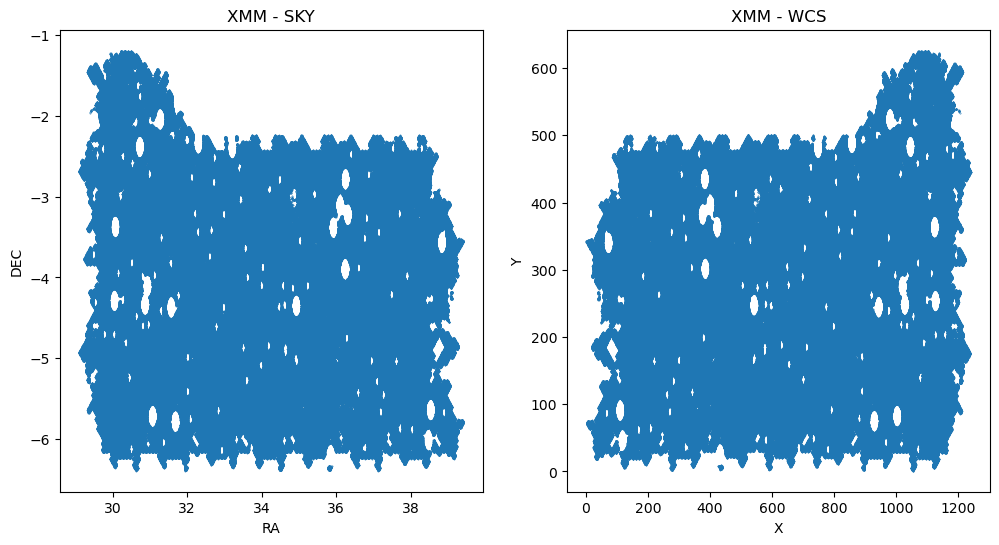

VVDS has 25 patches


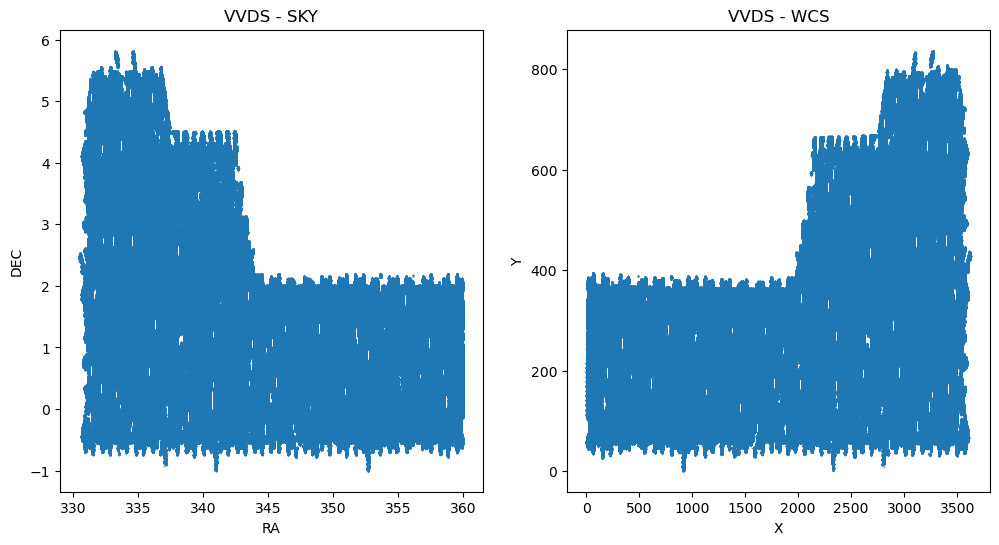

GAMA09H has 23 patches


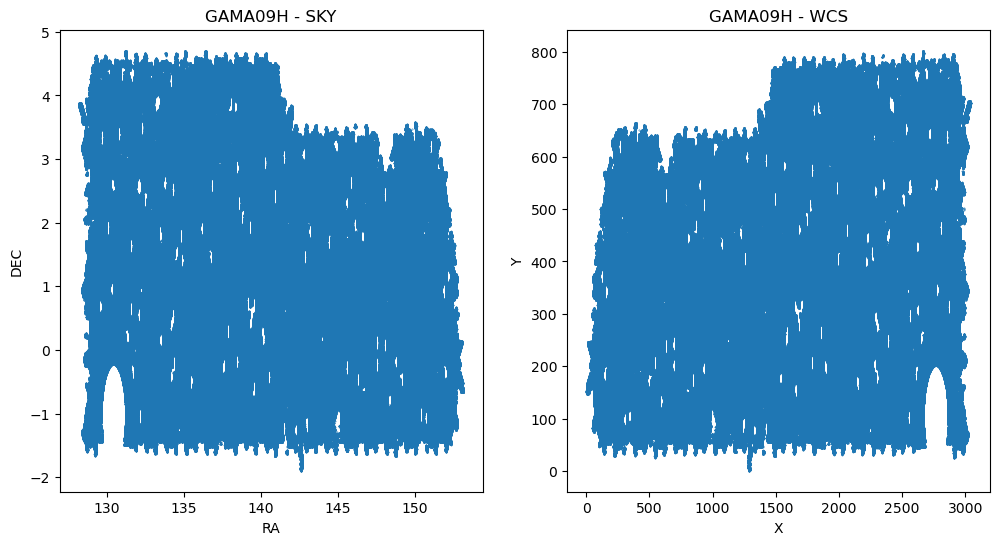

GAMA15H has 7 patches


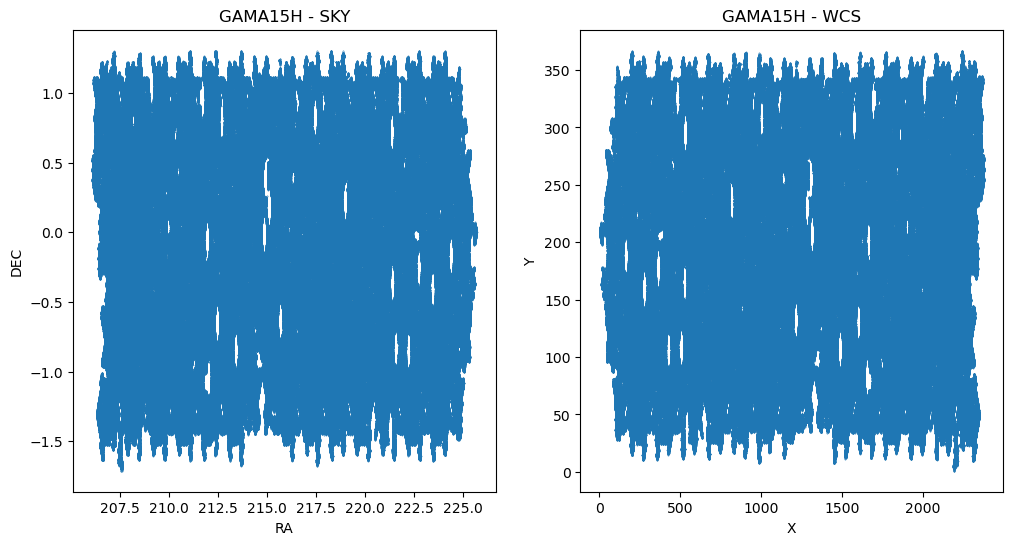

WIDE12H has 26 patches


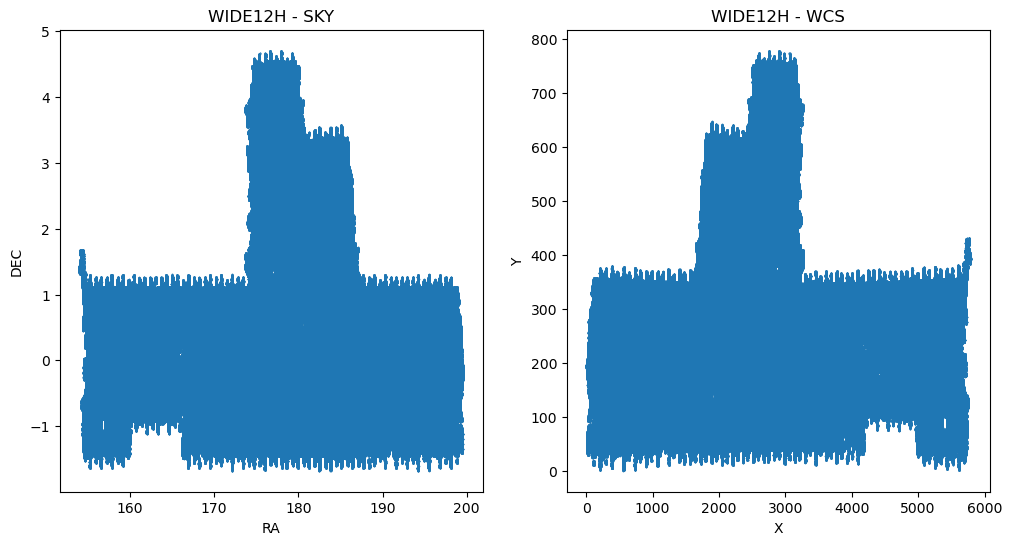

HECTOMAP has 13 patches


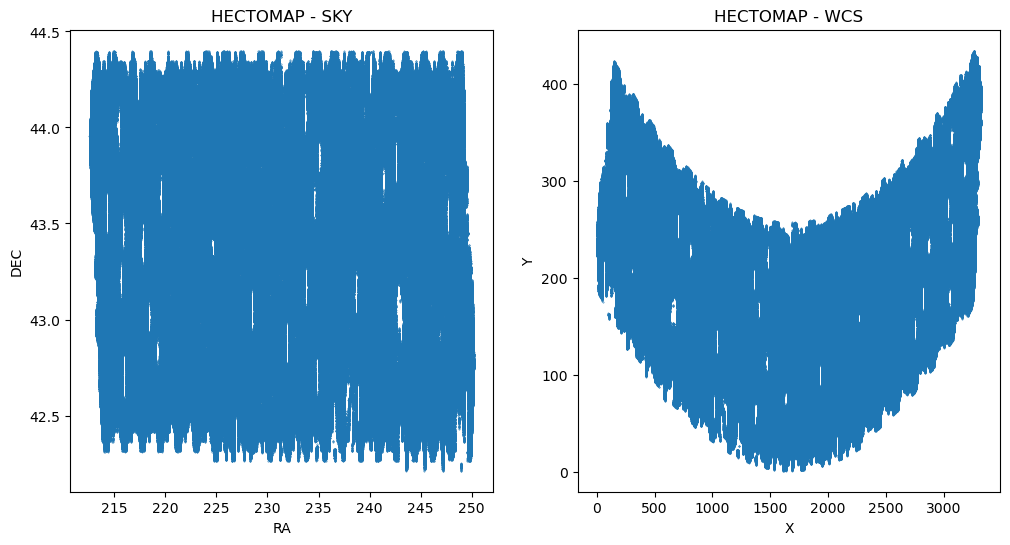

In [4]:
for field, n_patch in zip(name_fields, number_patches):
    print(f'{field} has {n_patch} patches')
    dat = np.concat([
        fits.getdata(f'/home/hedi/HSCNG/data/real/hscy3_shape_chopped_{field}_{n_patch}.fits')
        for n_patch in range(number_patches[name_fields.index(field)])
    ])
    w, x, y = coord2pix(dat['i_ra'], dat['i_dec'])

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].scatter(dat['i_ra'], dat['i_dec'], s=0.1)
    axes[0].set_xlabel('RA')
    axes[0].set_ylabel('DEC')
    axes[0].set_title(f'{field} - SKY')

    axes[1].scatter(x, y, s=0.1)
    axes[1].set_xlabel('X')
    axes[1].set_ylabel('Y')
    axes[1].set_title(f'{field} - WCS')
    plt.show()

## After rotation

XMM has 8 patches


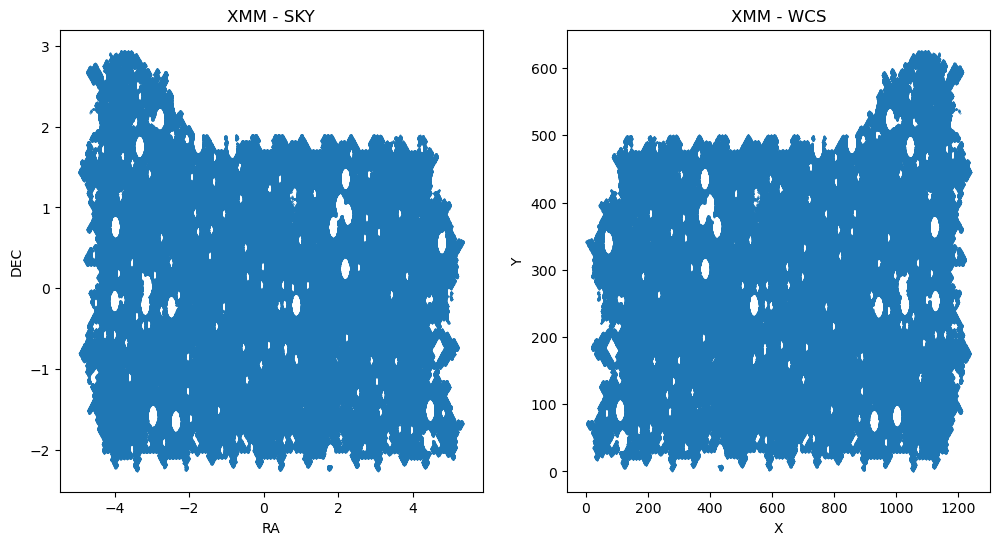

VVDS has 25 patches


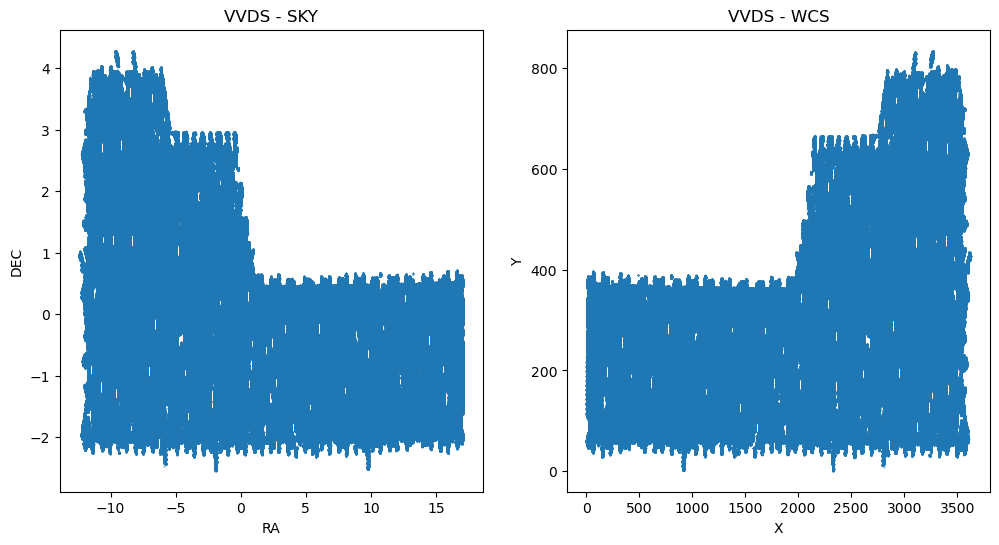

GAMA09H has 23 patches


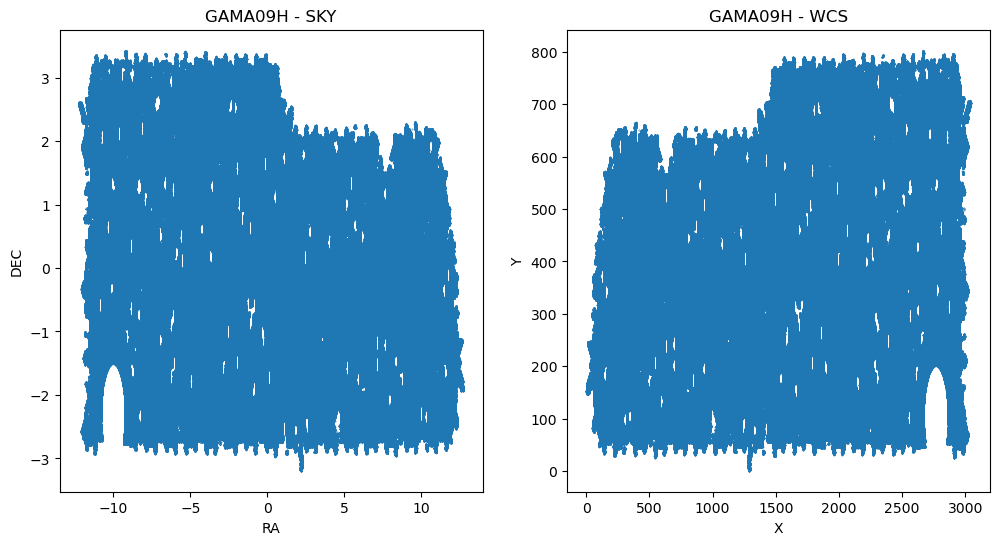

GAMA15H has 7 patches


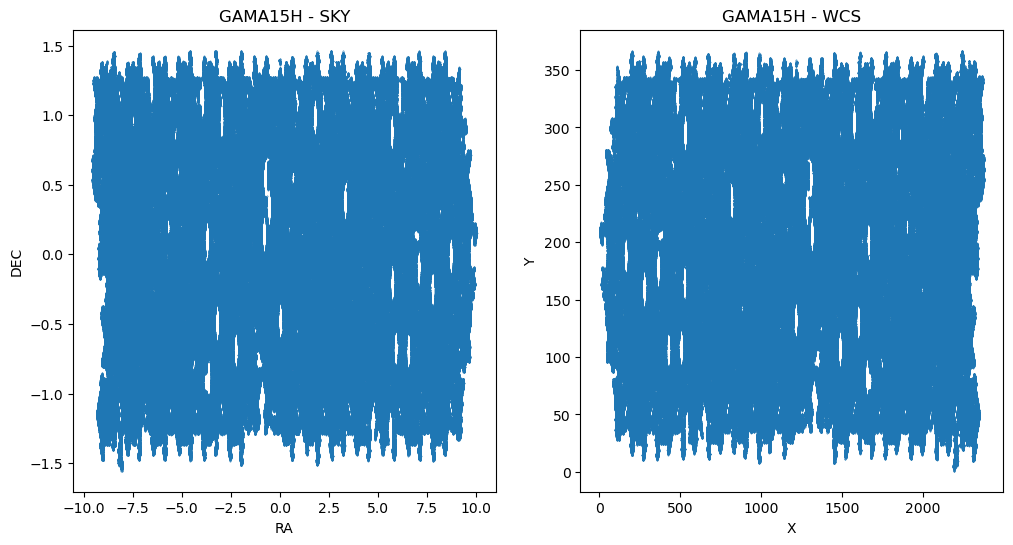

WIDE12H has 26 patches


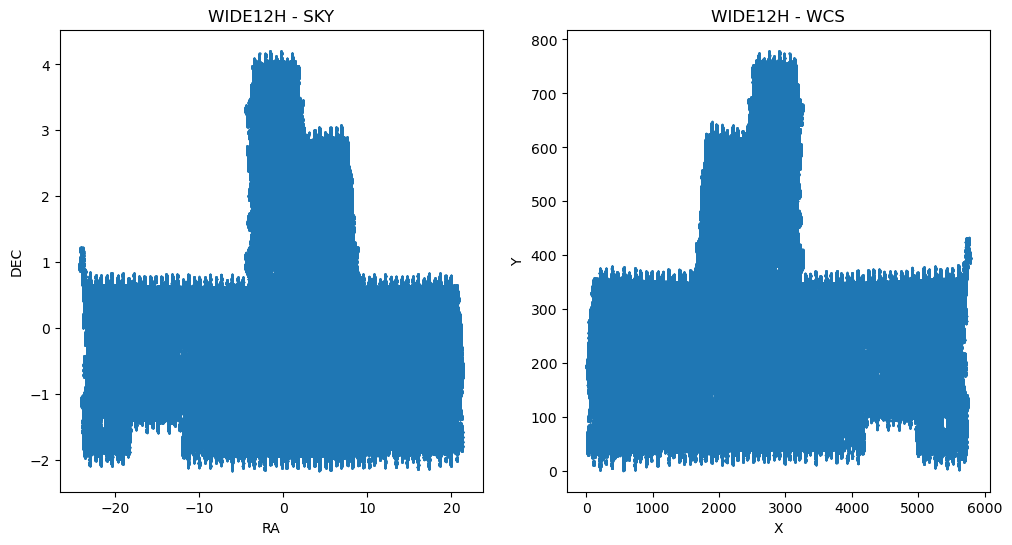

HECTOMAP has 13 patches


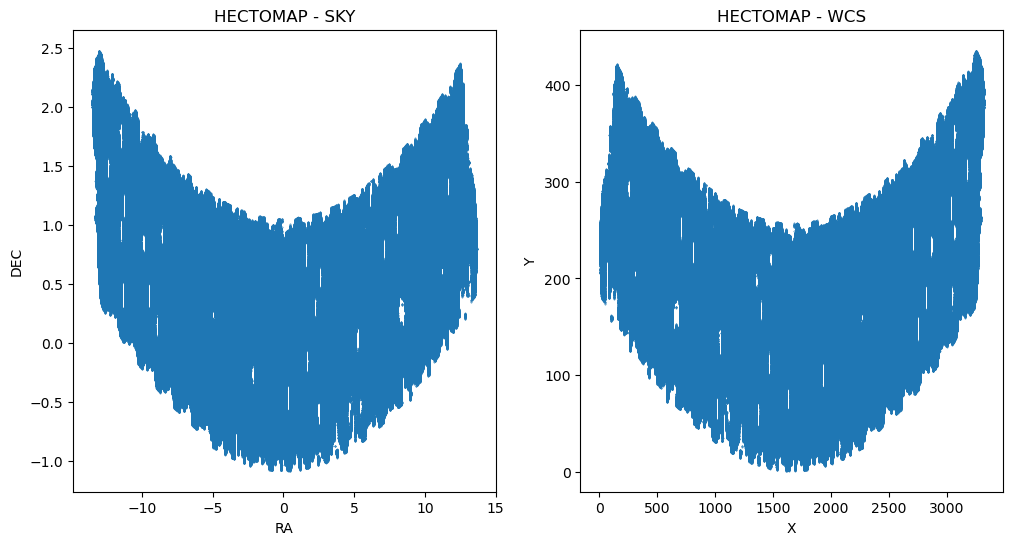

In [5]:
for field, n_patch in zip(name_fields, number_patches):
    print(f'{field} has {n_patch} patches')
    dat = np.concat([
        fits.getdata(f'/home/hedi/HSCNG/data/real/hscy3_shape_chopped_{field}_{n_patch}.fits')
        for n_patch in range(number_patches[name_fields.index(field)])
    ])
    ra, dec = rotate_to_00(dat['i_ra'], dat['i_dec'])   # rotate first
    w, x, y = coord2pix(ra, dec)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].scatter(ra, dec, s=0.1)
    axes[0].set_xlabel('RA')
    axes[0].set_ylabel('DEC')
    axes[0].set_title(f'{field} - SKY')

    axes[1].scatter(x, y, s=0.1)
    axes[1].set_xlabel('X')
    axes[1].set_ylabel('Y')
    axes[1].set_title(f'{field} - WCS')
    plt.show()

## maybe test by taking a manual rotation here?

In [44]:
import numpy as np

def rotate_sky_coordinates_y(ra, dec, angle_deg=40.0):
    """
    Rotate (ra, dec) on the sphere about the Cartesian y-axis.

    Parameters
    ----------
    ra, dec : array_like
        Sky coordinates in degrees.
    angle_deg : float
        Rotation angle in degrees. Use ~40 to move the footprint upward in dec.
    preserve_ra_range : bool
        If True, re-center/rescale RA so it stays in the original range.

    Returns
    -------
    ra_rot, dec_rot : ndarray
        Rotated coordinates in degrees.
    """
    ra = np.asarray(ra, dtype=float)
    dec = np.asarray(dec, dtype=float)

    if ra.shape != dec.shape:
        raise ValueError("ra and dec must have the same shape")

    a = np.deg2rad(angle_deg)
    ra_rad = np.deg2rad(ra)
    dec_rad = np.deg2rad(dec)

    # spherical -> Cartesian
    cos_dec = np.cos(dec_rad)
    x = cos_dec * np.cos(ra_rad)
    y = cos_dec * np.sin(ra_rad)
    z = np.sin(dec_rad)

    # rotate around y-axis
    x_rot = x * np.cos(a) + z * np.sin(a)
    y_rot = y
    z_rot = -x * np.sin(a) + z * np.cos(a)

    # Cartesian -> spherical
    ra_rot = np.rad2deg(np.arctan2(y_rot, x_rot))
    dec_rot = np.rad2deg(np.arcsin(np.clip(z_rot, -1.0, 1.0)))

    return ra_rot, dec_rot
